## Lesson 11: The big picture, yearly totals and trend

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/dataset_daily.csv", index_col="date", parse_dates=True)
FIG = "../figures/"

print(df.shape)
df.dtypes

(6209, 6)


consumption_gwh    float64
temp_ch            float64
holiday_share      float64
is_holiday            bool
weekday              int64
month                int64
dtype: object

In [2]:
yearly = df.groupby(df.index.year).agg(
    consumption_twh=("consumption_gwh", "sum"),
    temp_mean=("temp_ch", "mean"),
)
yearly["consumption_twh"] /= 1000      # GWh -> TWh
yearly.round(2)

,consumption_twh,temp_mean
date,,
2009,56.27,10.97
2010,58.52,9.94
2011,57.55,11.42
2012,57.68,10.81
2013,58.03,10.25
2014,56.41,11.48
2015,56.85,11.52
2016,56.86,10.93
2017,56.88,11.16


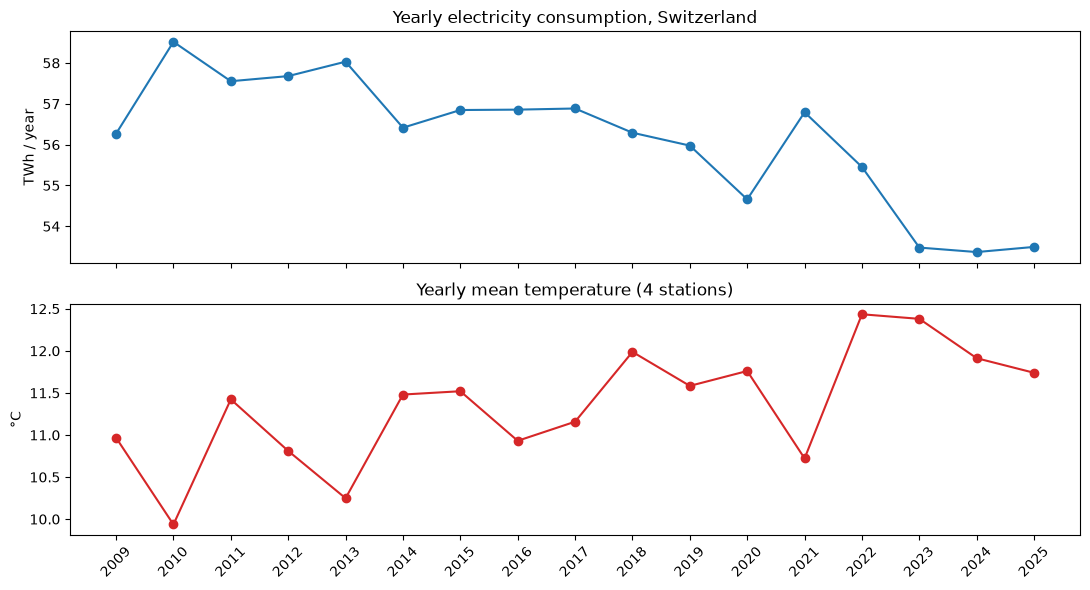

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax1.plot(yearly.index, yearly["consumption_twh"], marker="o")
ax1.set_ylabel("TWh / year")
ax1.set_title("Yearly electricity consumption, Switzerland")

ax2.plot(yearly.index, yearly["temp_mean"], marker="o", color="tab:red")
ax2.set_ylabel("°C")
ax2.set_title("Yearly mean temperature (4 stations)")
ax2.set_xticks(yearly.index)
ax2.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(FIG + "yearly_consumption_temperature.png", dpi=150, bbox_inches="tight")

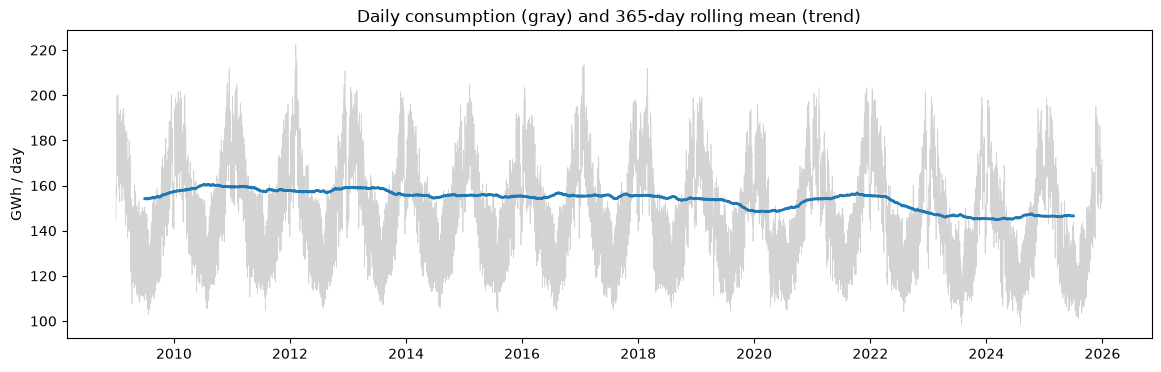

In [4]:
trend = df["consumption_gwh"].rolling(365, center=True).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["consumption_gwh"], lw=0.5, color="lightgray")
ax.plot(trend.index, trend, lw=2)
ax.set_ylabel("GWh / day")
ax.set_title("Daily consumption (gray) and 365-day rolling mean (trend)")
fig.savefig(FIG + "trend_rolling365.png", dpi=150, bbox_inches="tight")

## Lesson 12: The cycles, average week and average year

Mon    -1.1
Tue     0.5
Wed     0.7
Thu     0.6
Fri    -0.8
Sat   -13.4
Sun   -19.6
Name: consumption_gwh, dtype: float64


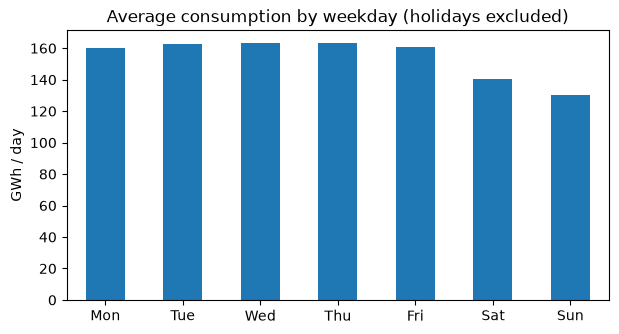

In [5]:
normal = ~df["is_holiday"]
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

week = df[normal].groupby("weekday")["consumption_gwh"].mean()
week.index = names

# difference compared with the average Monday-Friday, in %
week_pct = (week / week.iloc[:5].mean() - 1) * 100
print(week_pct.round(1))

ax = week.plot(kind="bar", figsize=(7, 3.5), rot=0)
ax.set_ylabel("GWh / day")
ax.set_title("Average consumption by weekday (holidays excluded)")
plt.savefig(FIG + "weekday_profile.png", dpi=150, bbox_inches="tight")

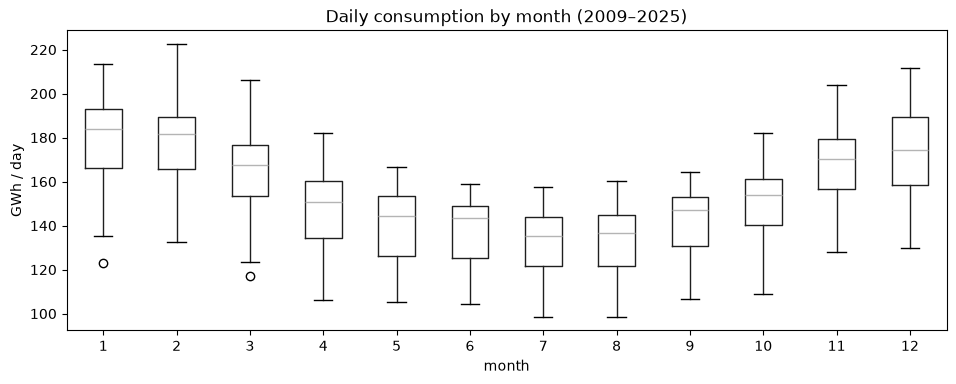

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
df.boxplot(column="consumption_gwh", by="month", ax=ax, grid=False)
ax.set_title("Daily consumption by month (2009–2025)")
ax.set_xlabel("month")
ax.set_ylabel("GWh / day")
fig.suptitle("")            # remove the automatic extra title pandas adds
fig.savefig(FIG + "monthly_boxplot.png", dpi=150, bbox_inches="tight")

In [7]:
wk = df["weekday"] < 5
print("normal weekday :", df[wk & normal]["consumption_gwh"].mean().round(1))
print("weekday holiday:", df[wk & ~normal]["consumption_gwh"].mean().round(1))
print("Saturday       :", df[(df["weekday"] == 5) & normal]["consumption_gwh"].mean().round(1))
print("Sunday         :", df[(df["weekday"] == 6) & normal]["consumption_gwh"].mean().round(1))

normal weekday : 162.0
weekday holiday: 130.6
Saturday       : 140.3
Sunday         : 130.3


## Lesson 13: Decomposition (trend + week + year + residual)

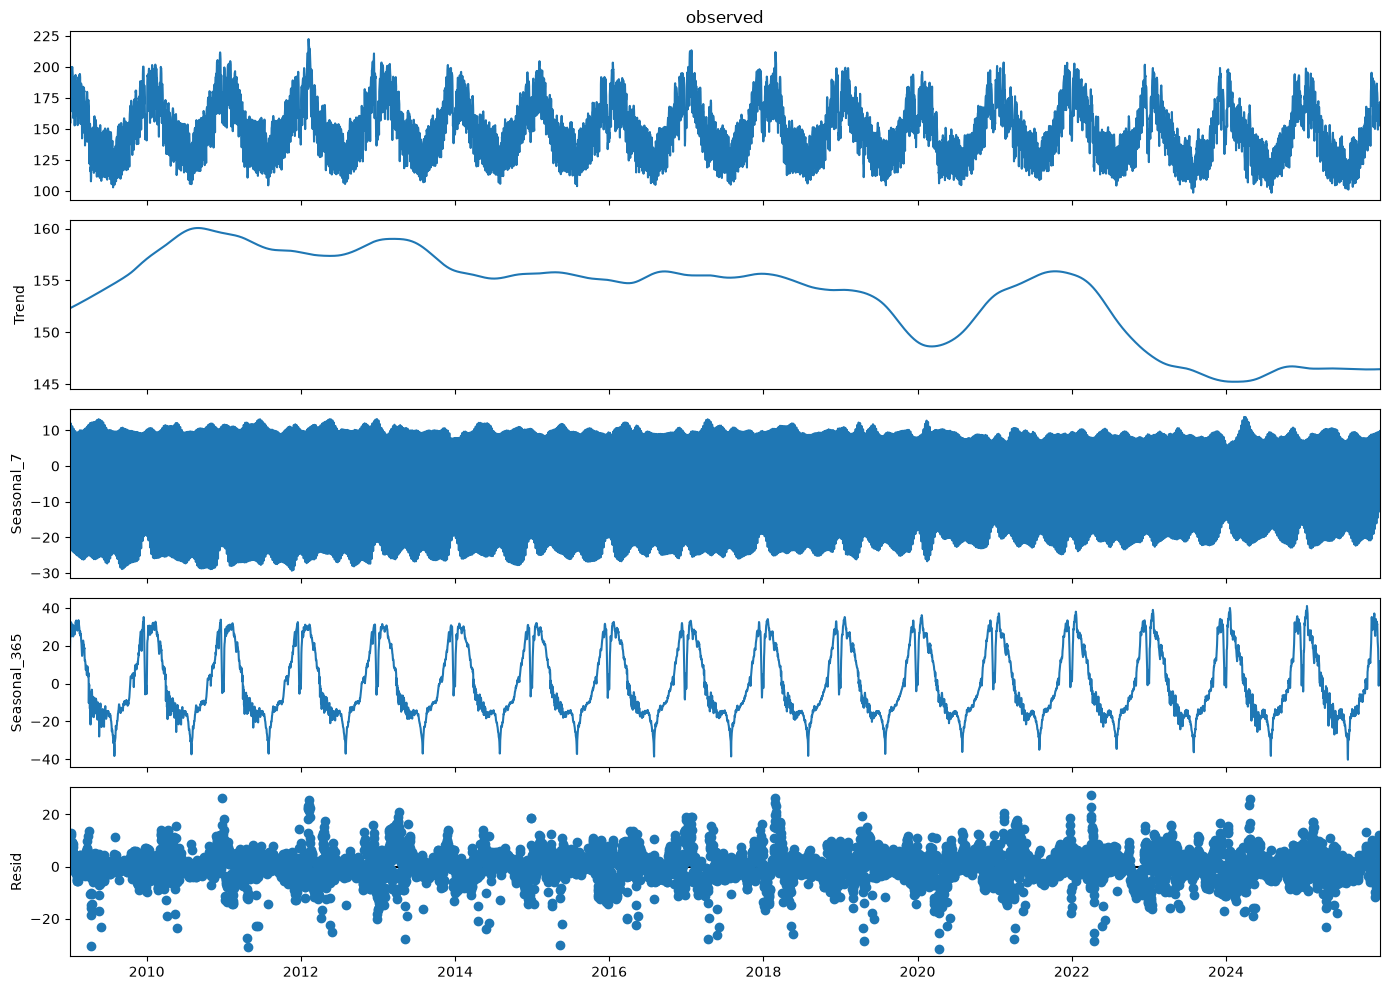

In [8]:
from statsmodels.tsa.seasonal import MSTL

y = df["consumption_gwh"]
res = MSTL(y, periods=(7, 365)).fit()

fig = res.plot()
fig.set_size_inches(14, 10)
fig.tight_layout()
fig.savefig(FIG + "mstl_decomposition.png", dpi=150, bbox_inches="tight")

In [9]:
comp = pd.DataFrame({
    "trend": res.trend,
    "weekly": res.seasonal["seasonal_7"],
    "yearly": res.seasonal["seasonal_365"],
    "residual": res.resid,
})
(comp.var() / y.var() * 100).round(1)     # share of the total variation, in %

trend        3.4
weekly      27.8
yearly      61.7
residual     6.7
dtype: float64

In [10]:
top = comp["residual"].abs().nlargest(10).index
pd.DataFrame({
    "residual": comp.loc[top, "residual"].round(1),
    "weekday": top.day_name(),
    "temp_ch": df.loc[top, "temp_ch"],
    "is_holiday": df.loc[top, "is_holiday"],
})

,residual,weekday,temp_ch,is_holiday
date,,,,
2020-04-13,-31.5,Monday,14.425,True
2011-04-25,-30.8,Monday,16.075,True
2009-04-13,-30.5,Monday,14.250,True
2015-05-14,-30.3,Thursday,18.375,True
2019-04-22,-28.5,Monday,15.250,True
2022-04-15,-28.5,Friday,15.300,True
2017-04-14,-27.8,Friday,12.300,True
2013-05-09,-27.8,Thursday,15.850,True
2021-04-02,-27.7,Friday,14.200,True


In [11]:
print("corr(residual, temperature):", comp["residual"].corr(df["temp_ch"]).round(3))

corr(residual, temperature): -0.19


all days, raw temperature     : -0.19
no holidays, temperature anomaly: -0.559


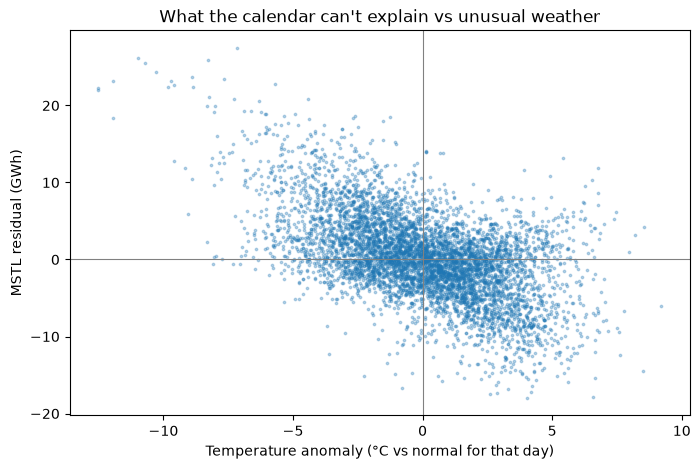

In [12]:
# "normal" temperature for each day of the year = average over 2009-2025
temp_normal = df.groupby(df.index.day_of_year)["temp_ch"].transform("mean")
df["temp_anomaly"] = df["temp_ch"] - temp_normal      # + = warmer than normal

mask = ~df["is_holiday"]
print("all days, raw temperature     :", comp["residual"].corr(df["temp_ch"]).round(3))
print("no holidays, temperature anomaly:", comp.loc[mask, "residual"].corr(df.loc[mask, "temp_anomaly"]).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df.loc[mask, "temp_anomaly"], comp.loc[mask, "residual"], s=3, alpha=0.3)
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Temperature anomaly (°C vs normal for that day)")
ax.set_ylabel("MSTL residual (GWh)")
ax.set_title("What the calendar can't explain vs unusual weather")
fig.savefig(FIG + "residual_vs_temp_anomaly.png", dpi=150, bbox_inches="tight")